# 02 — Estatística Descritiva e Visual

| | |
|---|---|
| **Projeto** | Análise Estatística — Spaceship Titanic (Pós-Graduação em Deep Learning — CIn/UFPE) |
| **Tickets** | [KAN-14](https://megamatic.atlassian.net/browse/KAN-14) — Resumos de variáveis categóricas · [KAN-16](https://megamatic.atlassian.net/browse/KAN-16) — Gráficos descritivos candidatos ao relatório |
| **Responsável** | Helton Gomes Soares de Lima |
| **Revisora** | Luciana Almeida |
| **Dependências** | [KAN-12](https://megamatic.atlassian.net/browse/KAN-12) (base tratada) · [KAN-15](https://megamatic.atlassian.net/browse/KAN-15) (resumos quantitativos) · [KAN-17](https://megamatic.atlassian.net/browse/KAN-17) (critério de outliers) |
| **Base de dados** | `data/processed/spaceship_titanic_clean.csv` — 8.693 passageiros × 22 colunas, 0 valores ausentes |
| **Saídas** | Tabelas de frequência e de contingência (KAN-14) · figuras em `report/figures/` a 300 DPI (KAN-16) |

## Objetivo

Descrever **quem eram os passageiros** do *Spaceship Titanic* (origem, destino, criossono, status VIP e localização da cabine) e **como cada perfil se relaciona com o desfecho `Transported`**, e transformar essas descobertas em figuras prontas para o relatório final.

## Notas de leitura

- **Escopo descritivo.** As proporções abaixo **descrevem associações observadas**; não indicam causa. A significância estatística dessas associações é testada na trilha de testes de hipóteses (KAN-25, qui-quadrado).
- **Efeito da imputação.** Cerca de 2,1% a 2,5% dos valores de cada variável categórica foram imputados pela moda na KAN-11. A Seção 1.3 compara as proporções da base tratada com as da base bruta, sem os ausentes, para mostrar que a imputação não altera as conclusões.
- **Taxa global de referência.** 50,36% dos passageiros foram transportados. Em todas as tabelas cruzadas, a coluna "Diferença (p.p.)" mede o quanto cada categoria se afasta dessa taxa.

In [1]:
# =============================================================================
# Configuração do ambiente, carga da base tratada e padrão visual
# =============================================================================
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# --- 1. Localização resiliente da raiz do projeto ----------------------------
# Funciona com o notebook aberto em notebooks/ (Jupyter local) ou na raiz.
RAIZ = Path("..") if Path("../data/processed").exists() else Path(".")
DATA_PATH = RAIZ / "data" / "processed" / "spaceship_titanic_clean.csv"
RAW_PATH = RAIZ / "data" / "raw" / "train.csv"
FIG_DIR = RAIZ / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Base tratada não encontrada. Execute a partir de notebooks/ ou da raiz "
        "do projeto; no Colab, faça upload de data/processed/spaceship_titanic_clean.csv."
    )

df = pd.read_csv(DATA_PATH)

# --- 2. Contratos de integridade herdados das KAN-11/KAN-12 -------------------
assert df.shape == (8693, 22), f"Shape inesperado: {df.shape}"
assert df.isna().sum().sum() == 0, "A base tratada não deve conter valores ausentes"
assert df["PassengerId"].is_unique, "PassengerId deve ser chave única"

N = len(df)
TAXA_GLOBAL = df["Transported"].mean() * 100

# --- 3. Variáveis categóricas do ticket KAN-14 --------------------------------
ORDEM = {
    "HomePlanet": ["Earth", "Europa", "Mars"],
    "Destination": ["TRAPPIST-1e", "55 Cancri e", "PSO J318.5-22"],
    "CryoSleep": [False, True],
    "VIP": [False, True],
    "CabinSide": ["P", "S"],
    "CabinDeck": ["A", "B", "C", "D", "E", "F", "G", "T"],
    "Transported": [False, True],
}
ROTULOS = {
    "CryoSleep": {False: "Acordado", True: "Em criossono"},
    "VIP": {False: "Não VIP", True: "VIP"},
    "CabinSide": {"P": "Bombordo (P)", "S": "Estibordo (S)"},
    "Transported": {False: "Não transportado", True: "Transportado"},
}

# --- 4. Padrão visual (provisório; a padronização final é da KAN-38) ----------
# Duas cores com luminâncias bem diferentes + hachura: legíveis em PDF colorido
# e em impressão preto e branco.
COR_TRANSP = "#1F4E79"      # azul escuro  -> Transportado
COR_NAO = "#F2B880"         # laranja claro -> Não transportado
COR_NEUTRA = "#5B7A99"      # cinza-azulado -> gráficos de uma só série
HACHURA_TRANSP = "//"
DPI = 300

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "figure.dpi": 110,
    "savefig.dpi": DPI,
    "savefig.bbox": "tight",
})


def fmt_pct(valor: float, casas: int = 1) -> str:
    # Percentual com vírgula decimal (padrão pt-BR).
    return f"{valor:.{casas}f}%".replace(".", ",")


def fmt_int(valor: int) -> str:
    # Inteiro com ponto de milhar (padrão pt-BR).
    return f"{valor:,}".replace(",", ".")


def salvar(fig, nome: str) -> Path:
    # Exporta a figura em PNG a 300 DPI em report/figures/.
    caminho = FIG_DIR / nome
    fig.savefig(caminho, dpi=DPI, facecolor="white")
    return caminho


print(f"Base: {fmt_int(N)} passageiros × {df.shape[1]} colunas | ausentes: 0")
print(f"Taxa global de transporte: {fmt_pct(TAXA_GLOBAL, 2)}")
print(f"Figuras serão salvas em: {FIG_DIR.as_posix()}")

Base: 8.693 passageiros × 22 colunas | ausentes: 0
Taxa global de transporte: 50,36%
Figuras serão salvas em: ../report/figures


---
# Parte I — KAN-14: Resumos de variáveis categóricas

## 1.1 Tabelas de frequência

Para cada variável categórica, apresentamos a **frequência absoluta** ($n$) e a **frequência relativa** (%) sobre os 8.693 passageiros.

In [2]:
# =============================================================================
# 1.1 Frequências absolutas e relativas
# =============================================================================
def tabela_frequencia(serie: pd.Series, ordem: list, rotulos: dict | None = None) -> pd.DataFrame:
    contagem = serie.value_counts().reindex(ordem, fill_value=0)
    tabela = pd.DataFrame({
        "Categoria": [rotulos.get(c, c) if rotulos else c for c in contagem.index],
        "n": contagem.values,
        "%": (contagem.values / len(serie) * 100).round(2),
    })
    return tabela


tabelas_freq = {}
for var, ordem in ORDEM.items():
    tab = tabela_frequencia(df[var], ordem, ROTULOS.get(var))
    assert tab["n"].sum() == N, f"Frequências de {var} não somam N"
    tabelas_freq[var] = tab

frequencias = pd.concat(tabelas_freq, names=["Variável", "linha"]).droplevel("linha")
display(frequencias)

,Categoria,n,%
Variável,,,
HomePlanet,Earth,4715,54.24
HomePlanet,Europa,2174,25.01
HomePlanet,Mars,1804,20.75
Destination,TRAPPIST-1e,6097,70.14
Destination,55 Cancri e,1800,20.71
Destination,PSO J318.5-22,796,9.16
CryoSleep,Acordado,5558,63.94
CryoSleep,Em criossono,3135,36.06
VIP,Não VIP,8494,97.71


## 1.2 Tabelas cruzadas com `Transported`

Para cada variável, a tabela mostra quantos passageiros de cada categoria foram ou não transportados, a **taxa de transporte da categoria** e a diferença em pontos percentuais (p.p.) em relação à taxa global de 50,36%.

In [3]:
# =============================================================================
# 1.2 Tabelas de contingência: variável × Transported
# =============================================================================
def tabela_cruzada(var: str) -> pd.DataFrame:
    ct = pd.crosstab(df[var], df["Transported"]).reindex(ORDEM[var])
    ct = ct.reindex(columns=[False, True], fill_value=0)
    total = ct.sum(axis=1)
    taxa = ct[True] / total * 100
    rotulos = ROTULOS.get(var, {})
    return pd.DataFrame({
        "Categoria": [rotulos.get(c, c) for c in ct.index],
        "n": total.values,
        "Não transportados": ct[False].values,
        "Transportados": ct[True].values,
        "Taxa de transporte (%)": taxa.round(2).values,
        "Diferença (p.p.)": (taxa - TAXA_GLOBAL).round(2).values,
    })


VARS_CRUZADAS = ["HomePlanet", "Destination", "CryoSleep", "VIP", "CabinSide", "CabinDeck"]
tabelas_cruzadas = {var: tabela_cruzada(var) for var in VARS_CRUZADAS}

for var, tab in tabelas_cruzadas.items():
    print(f"\n=== {var} × Transported ===")
    display(tab)

# Ranking das categorias mais afastadas da taxa global (com n >= 30)
ranking = (
    pd.concat(tabelas_cruzadas, names=["Variável", "linha"]).droplevel("linha").reset_index()
    .query("n >= 30")
    .assign(abs_dif=lambda d: d["Diferença (p.p.)"].abs())
    .sort_values("abs_dif", ascending=False)
    .drop(columns="abs_dif")
)
print("\n=== Categorias mais afastadas da taxa global (n >= 30) ===")
display(ranking.head(8).reset_index(drop=True))


=== HomePlanet × Transported ===


,Categoria,n,Não transportados,Transportados,Taxa de transporte (%),Diferença (p.p.)
0,Earth,4715,2719,1996,42.33,-8.03
1,Europa,2174,738,1436,66.05,15.69
2,Mars,1804,858,946,52.44,2.08



=== Destination × Transported ===


,Categoria,n,Não transportados,Transportados,Taxa de transporte (%),Diferença (p.p.)
0,TRAPPIST-1e,6097,3218,2879,47.22,-3.14
1,55 Cancri e,1800,702,1098,61.00,10.64
2,PSO J318.5-22,796,395,401,50.38,0.01



=== CryoSleep × Transported ===


...

,Categoria,n,Não transportados,Transportados,Taxa de transporte (%),Diferença (p.p.)
0,Bombordo (P),4309,2366,1943,45.09,-5.27
1,Estibordo (S),4384,1949,2435,55.54,5.18



=== CabinDeck × Transported ===


,Categoria,n,Não transportados,Transportados,Taxa de transporte (%),Diferença (p.p.)
0,A,262,130,132,50.38,0.02
1,B,817,221,596,72.95,22.59
2,C,761,243,518,68.07,17.71
3,D,507,287,220,43.39,-6.97
4,E,885,566,319,36.05,-14.32
5,F,2868,1611,1257,43.83,-6.53
6,G,2588,1253,1335,51.58,1.22
7,T,5,4,1,20.00,-30.36



=== Categorias mais afastadas da taxa global (n >= 30) ===


,Variável,Categoria,n,Não transportados,Transportados,Taxa de transporte (%),Diferença (p.p.)
0,CryoSleep,Em criossono,3135,581,2554,81.47,31.10
1,CabinDeck,B,817,221,596,72.95,22.59
2,CabinDeck,C,761,243,518,68.07,17.71
3,CryoSleep,Acordado,5558,3734,1824,32.82,-17.54
4,HomePlanet,Europa,2174,738,1436,66.05,15.69
5,CabinDeck,E,885,566,319,36.05,-14.32
6,VIP,VIP,199,123,76,38.19,-12.17
7,Destination,55 Cancri e,1800,702,1098,61.00,10.64


## 1.3 Sensibilidade à imputação

Comparamos a distribuição de cada variável na base tratada com a da base bruta, desconsiderando os ausentes. Se a imputação pela moda tivesse distorcido as proporções, as diferenças seriam grandes.

In [4]:
# =============================================================================
# 1.3 Base tratada vs. base bruta (sem ausentes)
# =============================================================================
raw = pd.read_csv(RAW_PATH)
cabin = raw["Cabin"].str.split("/", expand=True)
raw["CabinDeck"], raw["CabinSide"] = cabin[0], cabin[2]

linhas = []
for var in VARS_CRUZADAS:
    bruta = raw[var].dropna()
    for cat in ORDEM[var]:
        p_bruta = (bruta == cat).mean() * 100
        p_trat = (df[var] == cat).mean() * 100
        t_bruta = raw.loc[raw[var] == cat, "Transported"].mean() * 100
        t_trat = df.loc[df[var] == cat, "Transported"].mean() * 100
        linhas.append({
            "Variável": var,
            "Categoria": ROTULOS.get(var, {}).get(cat, cat),
            "% bruta": p_bruta,
            "% tratada": p_trat,
            "Dif. % (p.p.)": p_trat - p_bruta,
            "Taxa transp. bruta": t_bruta,
            "Taxa transp. tratada": t_trat,
            "Dif. taxa (p.p.)": t_trat - t_bruta,
        })

sensibilidade = pd.DataFrame(linhas)
display(sensibilidade.round(2))
print(f"Maior diferença de proporção: {sensibilidade['Dif. % (p.p.)'].abs().max():.2f} p.p.")
print(f"Maior diferença de taxa de transporte (categorias com n >= 30): "
      f"{sensibilidade.loc[sensibilidade['Categoria'] != 'T', 'Dif. taxa (p.p.)'].abs().max():.2f} p.p.")

,Variável,Categoria,% bruta,% tratada,Dif. % (p.p.),Taxa transp. bruta,Taxa transp. tratada,Dif. taxa (p.p.)
0,HomePlanet,Earth,54.19,54.24,0.05,42.39,42.33,-0.06
1,HomePlanet,Europa,25.09,25.01,-0.09,65.88,66.05,0.17
2,HomePlanet,Mars,20.71,20.75,0.04,52.30,52.44,0.14
3,Destination,TRAPPIST-1e,69.50,70.14,0.64,47.12,47.22,0.10
4,Destination,55 Cancri e,21.15,20.71,-0.44,61.00,61.00,0.00
5,Destination,PSO J318.5-22,9.35,9.16,-0.20,50.38,50.38,0.00
6,CryoSleep,Acordado,64.17,63.94,-0.23,32.89,32.82,-0.07
7,CryoSleep,Em criossono,35.83,36.06,0.23,81.76,81.47,-0.29
8,VIP,Não VIP,97.66,97.71,0.05,50.63,50.65,0.01
9,VIP,VIP,2.34,2.29,-0.05,38.19,38.19,0.00


Maior diferença de proporção: 0.64 p.p.
Maior diferença de taxa de transporte (categorias com n >= 30): 0.77 p.p.


## 1.4 Interpretação

### Perfil dos passageiros

- **Origem.** A maioria vem da **Terra (54,2%)**, seguida de **Europa (25,0%)** e **Marte (20,8%)**.
- **Destino.** O destino dominante é **TRAPPIST-1e (70,1%)**; 55 Cancri e recebe 20,7% e PSO J318.5-22, 9,2%.
- **Criossono.** Pouco mais de um terço dos passageiros viajou em **criossono (36,1%)**.
- **VIP.** O status VIP é raro: **2,3% (199 passageiros)**.
- **Cabine.** Os lados do navio são equilibrados (49,6% bombordo, 50,4% estibordo). Os decks **F (33,0%)** e **G (29,8%)** concentram quase dois terços dos passageiros, e o deck **T** tem apenas **5 passageiros (0,06%)**.
- **Desfecho.** O alvo é **balanceado**: 50,4% transportados e 49,6% não transportados. Isso favorece a modelagem, pois nenhuma classe é rara, e significa que um classificador ingênuo acerta só cerca de metade dos casos.

### Associações com `Transported`

- **Criossono é a associação mais forte.** **81,5%** dos passageiros em criossono foram transportados, contra **32,8%** dos acordados, uma diferença de quase 49 p.p. É o principal sinal descritivo do dataset.
- **Origem.** Passageiros de **Europa** têm a maior taxa de transporte (**66,1%**, +15,7 p.p. acima da média); os da **Terra**, a menor (**42,3%**, −8,0 p.p.). Marte fica próximo da média (52,4%).
- **Destino.** Quem ia para **55 Cancri e** teve taxa de **61,0%** (+10,6 p.p.); TRAPPIST-1e ficou abaixo da média (47,2%).
- **Deck da cabine.** Os decks **B (73,0%)** e **C (68,1%)** se destacam acima da média, e o deck **E (36,0%)** abaixo. A taxa de 20% do deck T se baseia em apenas 5 pessoas e **não deve ser interpretada**.
- **Lado da cabine.** Estibordo tem taxa um pouco maior (**55,5%** contra **45,1%** em bombordo).
- **VIP.** VIPs foram transportados com menos frequência (**38,2%** contra 50,7%), mas o grupo é pequeno (199 pessoas), o que torna essa estimativa menos estável.

### Sensibilidade e cautelas

- A imputação pela moda alterou as proporções em **no máximo 0,64 p.p.** (TRAPPIST-1e, a moda de `Destination`), e as taxas de transporte por categoria mudam **no máximo 0,77 p.p.** (deck A). As conclusões acima valem tanto para a base tratada quanto para a bruta.
- Essas diferenças de taxa são **associações descritivas**. Variáveis como criossono, origem e deck se sobrepõem: **73% dos passageiros de Europa estão nos decks B e C**, enquanto praticamente todos os da Terra (99,98%) estão nos decks E, F e G. Parte da alta taxa dos decks B e C pode, portanto, refletir a origem dos passageiros, e não o deck em si. A significância de cada associação é avaliada na KAN-25.
- **Atenção para a KAN-25:** se `CabinDeck` entrar no teste qui-quadrado, o deck T viola o pressuposto de frequência esperada maior que 5 por célula. Recomenda-se agrupá-lo com outro deck ou excluí-lo apenas do teste.

---
# Parte II — KAN-16: Gráficos descritivos candidatos ao relatório

Todos os gráficos seguem o mesmo padrão: título descritivo, eixos com unidade, legenda explícita, anotações numéricas, fonte de 10 a 12 pt e paleta legível em PDF colorido e em preto e branco (azul escuro com hachura para **Transportado**, laranja claro para **Não transportado**). As figuras são exportadas a **300 DPI** em `report/figures/`.

> **Nomes provisórios.** Os arquivos usam o prefixo `desc_`. A numeração final (`fig_01_...`) e a padronização de estilo entre todos os capítulos ficam para a KAN-38.

In [5]:
# =============================================================================
# Funções auxiliares para barras 100% empilhadas
# =============================================================================
def barras_100_empilhadas(ax, var: str, titulo: str, rotulo_x: str):
    tab = tabelas_cruzadas[var]
    x = np.arange(len(tab))
    # taxa sem arredondamento prévio (evita 66,05 -> "66,0%")
    taxa = (tab["Transportados"] / tab["n"] * 100).to_numpy()

    b_t = ax.bar(x, taxa, color=COR_TRANSP, hatch=HACHURA_TRANSP, edgecolor="white",
                 linewidth=0.8, label="Transportado")
    b_n = ax.bar(x, 100 - taxa, bottom=taxa, color=COR_NAO, edgecolor="white",
                 linewidth=0.8, label="Não transportado")

    for xi, t in zip(x, taxa):
        ax.text(xi, t / 2, fmt_pct(t), ha="center", va="center", color="white",
                fontsize=10, fontweight="bold",
                bbox=dict(facecolor=COR_TRANSP, edgecolor="none", pad=1.5))
        ax.text(xi, t + (100 - t) / 2, fmt_pct(100 - t), ha="center", va="center",
                color="black", fontsize=10)

    ax.axhline(TAXA_GLOBAL, color="black", linestyle="--", linewidth=1)


    ax.set_xticks(x)
    ax.set_xticklabels([f"{c}\n(n = {fmt_int(n)})" for c, n in zip(tab["Categoria"], tab["n"])])
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.set_ylabel("Passageiros da categoria (%)")
    ax.set_xlabel(rotulo_x)
    ax.set_title(titulo)
    linha_media = plt.Line2D([0], [0], color="black", linestyle="--", linewidth=1,
                             label=f"Média geral: {fmt_pct(TAXA_GLOBAL)}")
    ax.legend(handles=[b_t, b_n, linha_media], loc="upper center", bbox_to_anchor=(0.5, -0.22),
              ncol=3, frameon=False)
    ax.grid(axis="x", visible=False)

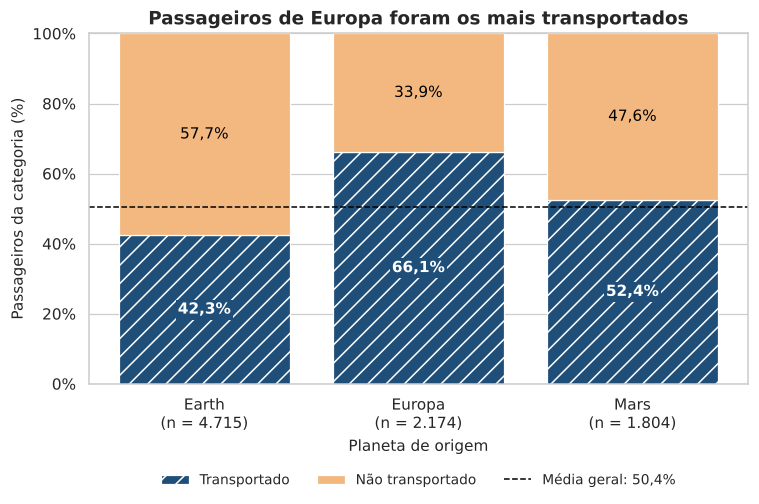

In [6]:
# =============================================================================
# Figura 1 — Taxa de transporte por planeta de origem
# =============================================================================
fig, ax = plt.subplots(figsize=(7, 4.8))
barras_100_empilhadas(ax, "HomePlanet",
                      "Passageiros de Europa foram os mais transportados",
                      "Planeta de origem")
fig.tight_layout()
salvar(fig, "desc_01_homeplanet_transported.png")
plt.show()

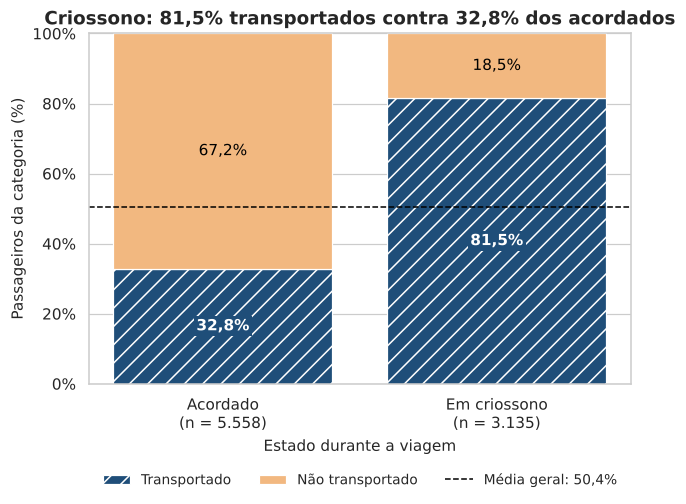

In [7]:
# =============================================================================
# Figura 2 — Taxa de transporte por criossono
# =============================================================================
fig, ax = plt.subplots(figsize=(6, 4.8))
barras_100_empilhadas(ax, "CryoSleep",
                      "Criossono: 81,5% transportados contra 32,8% dos acordados",
                      "Estado durante a viagem")
fig.tight_layout()
salvar(fig, "desc_02_cryosleep_transported.png")
plt.show()

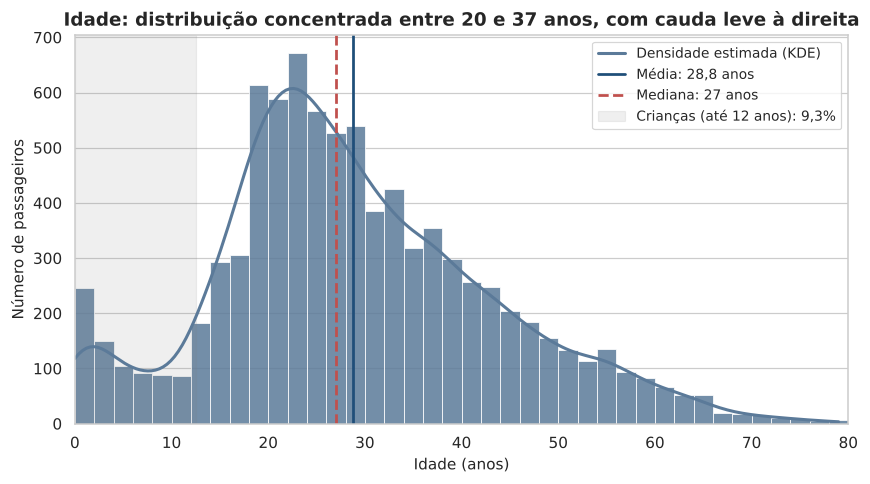

In [8]:
# =============================================================================
# Figura 3 — Distribuição de idade (histograma + KDE)
# =============================================================================
idade = df["Age"]
media, mediana = idade.mean(), idade.median()
pct_criancas = (idade <= 12).mean() * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(idade, binwidth=2, binrange=(0, 80), kde=True, color=COR_NEUTRA,
             edgecolor="white", linewidth=0.5, alpha=0.85, ax=ax,
             line_kws={"linewidth": 2, "color": "black"})
ax.lines[0].set_label("Densidade estimada (KDE)")

ax.axvline(media, color=COR_TRANSP, linestyle="-", linewidth=1.8,
           label=f"Média: {fmt_pct(media, 1).rstrip('%')} anos")
ax.axvline(mediana, color="#C0504D", linestyle="--", linewidth=1.8,
           label=f"Mediana: {mediana:.0f} anos")
ax.axvspan(0, 12.5, color="grey", alpha=0.12,
           label=f"Crianças (até 12 anos): {fmt_pct(pct_criancas)}")

ax.set_xlim(0, 80)
ax.set_xlabel("Idade (anos)")
ax.set_ylabel("Número de passageiros")
ax.set_title("Idade: distribuição concentrada entre 20 e 37 anos, com cauda leve à direita")
ax.legend(loc="upper right", frameon=True)
ax.grid(axis="x", visible=False)
fig.tight_layout()
salvar(fig, "desc_03_age_hist_kde.png")
plt.show()

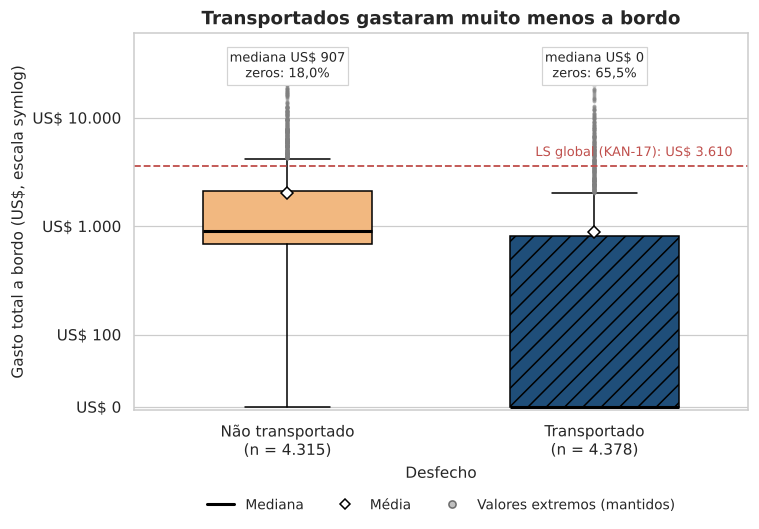

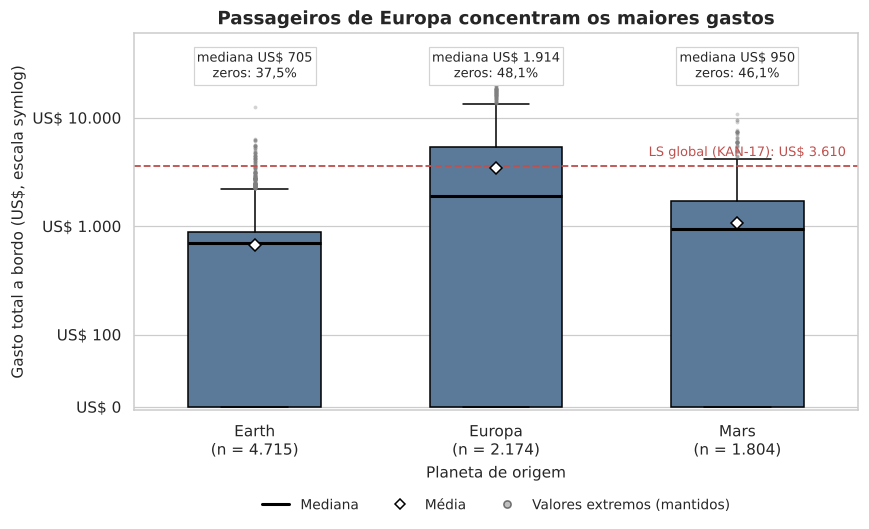

,n,media,mediana,zeros
Transported,,,,
False,4315,2011.89,907.0,17.96
True,4378,891.15,0.0,65.53


,n,media,mediana,zeros
HomePlanet,,,,
Earth,4715,675.24,705.0,37.45
Europa,2174,3444.00,1914.0,48.11
Mars,1804,1059.73,950.0,46.12


In [9]:
# =============================================================================
# Figuras 4 e 5 — Boxplots de TotalSpend
# =============================================================================
# Os quartis e os bigodes (1,5 × IQR) são calculados na ESCALA ORIGINAL, como na
# KAN-17; apenas o EIXO usa escala symlog (linear perto de zero, logarítmica
# depois), para que a caixa não fique achatada pelos zeros. A linha tracejada
# marca o limite superior global da KAN-17 (LS = US$ 3.610).
Q1_TS, Q3_TS = df["TotalSpend"].quantile([0.25, 0.75])
LS_KAN17 = Q3_TS + 1.5 * (Q3_TS - Q1_TS)
assert LS_KAN17 == 3610.0, "LS divergente da KAN-17"


def boxplot_totalspend(ax, grupos: list, rotulos: list, cores: list, hachuras: list, titulo: str, rotulo_x: str):
    dados = [df.loc[mask, "TotalSpend"].to_numpy() for mask in grupos]
    bp = ax.boxplot(dados, whis=1.5, widths=0.55, patch_artist=True, showmeans=True,
                    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6),
                    medianprops=dict(color="black", linewidth=2),
                    flierprops=dict(marker="o", markersize=2.5, alpha=0.35,
                                    markerfacecolor="grey", markeredgecolor="none"))
    for caixa, cor, hachura in zip(bp["boxes"], cores, hachuras):
        caixa.set_facecolor(cor)
        caixa.set_hatch(hachura)
        caixa.set_edgecolor("black")

    ax.set_yscale("symlog", linthresh=100, linscale=0.6)
    ax.set_ylim(-5, 60000)
    ax.yaxis.set_major_locator(mticker.FixedLocator([0, 100, 1000, 10000]))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"US$ {fmt_int(int(v))}"))
    ax.yaxis.set_minor_locator(mticker.NullLocator())

    ax.axhline(LS_KAN17, color="#C0504D", linestyle="--", linewidth=1.2)
    ax.text(len(dados) + 0.45, LS_KAN17 * 1.15, "LS global (KAN-17): US$ 3.610",
            ha="right", va="bottom", fontsize=8.5, color="#C0504D")

    for i, d in enumerate(dados, start=1):
        pct_zero = (d == 0).mean() * 100
        ax.text(i, 30000, f"mediana US$ {fmt_int(int(np.median(d)))}\nzeros: {fmt_pct(pct_zero)}",
                ha="center", va="center", fontsize=8.5,
                bbox=dict(facecolor="white", edgecolor="lightgrey", pad=2))

    ax.set_xticks(range(1, len(dados) + 1))
    ax.set_xticklabels([f"{r}\n(n = {fmt_int(len(d))})" for r, d in zip(rotulos, dados)])
    ax.set_xlabel(rotulo_x)
    ax.set_ylabel("Gasto total a bordo (US$, escala symlog)")
    ax.set_title(titulo)
    ax.grid(axis="x", visible=False)


from matplotlib.lines import Line2D
legenda_box = [
    Line2D([0], [0], color="black", linewidth=2, label="Mediana"),
    Line2D([0], [0], marker="D", color="none", markerfacecolor="white", markeredgecolor="black", label="Média"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="grey", alpha=0.5, label="Valores extremos (mantidos)"),
]

# --- Figura 4: por Transported ---
fig, ax = plt.subplots(figsize=(7, 5))
boxplot_totalspend(
    ax,
    grupos=[~df["Transported"], df["Transported"]],
    rotulos=["Não transportado", "Transportado"],
    cores=[COR_NAO, COR_TRANSP],
    hachuras=["", HACHURA_TRANSP],
    titulo="Transportados gastaram muito menos a bordo",
    rotulo_x="Desfecho",
)
ax.legend(handles=legenda_box, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
fig.tight_layout()
salvar(fig, "desc_04_totalspend_box_transported.png")
plt.show()

# --- Figura 5: por HomePlanet ---
fig, ax = plt.subplots(figsize=(8, 5))
boxplot_totalspend(
    ax,
    grupos=[df["HomePlanet"] == p for p in ORDEM["HomePlanet"]],
    rotulos=ORDEM["HomePlanet"],
    cores=[COR_NEUTRA] * 3,
    hachuras=[""] * 3,
    titulo="Passageiros de Europa concentram os maiores gastos",
    rotulo_x="Planeta de origem",
)
ax.legend(handles=legenda_box, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
fig.tight_layout()
salvar(fig, "desc_05_totalspend_box_homeplanet.png")
plt.show()

# Números citados na interpretação
resumo_box = df.groupby("Transported")["TotalSpend"].agg(
    n="size", media="mean", mediana="median", zeros=lambda s: (s == 0).mean() * 100)
resumo_box_planeta = df.groupby("HomePlanet")["TotalSpend"].agg(
    n="size", media="mean", mediana="median", zeros=lambda s: (s == 0).mean() * 100)
display(resumo_box.round(2))
display(resumo_box_planeta.round(2))

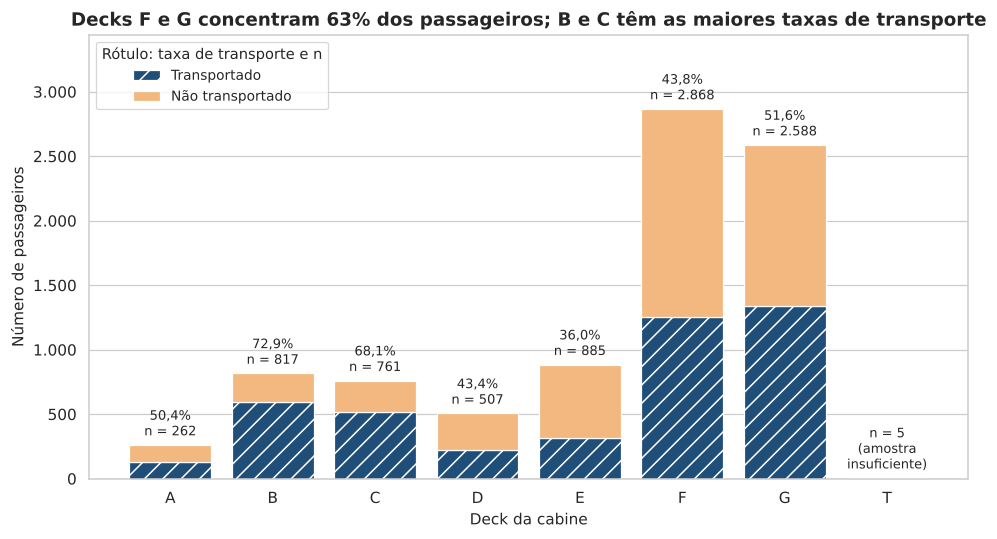

In [10]:
# =============================================================================
# Figura 6 — Passageiros por deck da cabine e taxa de transporte
# =============================================================================
tab_deck = tabelas_cruzadas["CabinDeck"]
x = np.arange(len(tab_deck))

fig, ax = plt.subplots(figsize=(9, 5))
b_t = ax.bar(x, tab_deck["Transportados"], color=COR_TRANSP, hatch=HACHURA_TRANSP,
             edgecolor="white", linewidth=0.8, label="Transportado")
b_n = ax.bar(x, tab_deck["Não transportados"], bottom=tab_deck["Transportados"], color=COR_NAO,
             edgecolor="white", linewidth=0.8, label="Não transportado")

taxas_deck = tab_deck["Transportados"] / tab_deck["n"] * 100
for xi, n, taxa, deck in zip(x, tab_deck["n"], taxas_deck, tab_deck["Categoria"]):
    if deck == "T":
        texto = f"n = {n}\n(amostra\ninsuficiente)"
    else:
        texto = f"{fmt_pct(taxa)}\nn = {fmt_int(n)}"
    ax.text(xi, n + 40, texto, ha="center", va="bottom", fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels(tab_deck["Categoria"])
ax.set_ylim(0, tab_deck["n"].max() * 1.2)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: fmt_int(int(v))))
ax.set_xlabel("Deck da cabine")
ax.set_ylabel("Número de passageiros")
ax.set_title("Decks F e G concentram 63% dos passageiros; B e C têm as maiores taxas de transporte")
ax.legend(handles=[b_t, b_n], loc="upper left", frameon=True,
          title="Rótulo: taxa de transporte e n")
ax.grid(axis="x", visible=False)
fig.tight_layout()
salvar(fig, "desc_06_cabindeck_transported.png")
plt.show()

In [11]:
# =============================================================================
# Conferência das figuras exportadas (critério de aceitação da KAN-16)
# =============================================================================
from PIL import Image

figuras = sorted(FIG_DIR.glob("desc_*.png"))
registro = []
for caminho in figuras:
    with Image.open(caminho) as img:
        dpi = img.info.get("dpi", (None, None))[0]
        registro.append({"Arquivo": caminho.name, "Largura (px)": img.width,
                         "Altura (px)": img.height, "DPI": round(dpi) if dpi else None})

conferencia = pd.DataFrame(registro)
display(conferencia)
assert len(figuras) >= 5, "A KAN-16 exige no mínimo 5 gráficos"
assert (conferencia["DPI"] == DPI).all(), "Todas as figuras devem estar a 300 DPI"
print(f"{len(figuras)} figuras exportadas a {DPI} DPI em {FIG_DIR.as_posix()}")

,Arquivo,Largura (px),Altura (px),DPI
0,desc_01_homeplanet_transported.png,2070,1376,300
1,desc_02_cryosleep_transported.png,1872,1376,300
2,desc_03_age_hist_kde.png,2374,1320,300
3,desc_04_totalspend_box_transported.png,2070,1444,300
4,desc_05_totalspend_box_homeplanet.png,2370,1444,300
5,desc_06_cabindeck_transported.png,2720,1470,300


6 figuras exportadas a 300 DPI em ../report/figures


## 2.1 Leitura das figuras

| Figura | Arquivo | O que mostra |
|---|---|---|
| 1 | `desc_01_homeplanet_transported.png` | Europa tem a maior taxa de transporte (66,1%) e a Terra, a menor (42,3%); Marte fica perto da média (52,4%). |
| 2 | `desc_02_cryosleep_transported.png` | A maior diferença do dataset: 81,5% dos passageiros em criossono foram transportados, contra 32,8% dos acordados. |
| 3 | `desc_03_age_hist_kde.png` | Idade aproximadamente simétrica (média de 28,8 anos e mediana de 27), concentrada entre 20 e 37 anos; 9,3% são crianças de até 12 anos, com um pico em idade 0 (bebês). |
| 4 | `desc_04_totalspend_box_transported.png` | Entre os transportados, a mediana do gasto total é zero e 65,5% não gastaram nada (média de US$ 891). Entre os não transportados, só 18,0% têm gasto zero, e a mediana é de US$ 907 (média de US$ 2.012). |
| 5 | `desc_05_totalspend_box_homeplanet.png` | Europa concentra os maiores gastos (mediana de US$ 1.914 e média de US$ 3.444), contra medianas de US$ 705 na Terra e US$ 950 em Marte, apesar de Europa ter mais passageiros com gasto zero (48,1%). Os pontos acima do bigode são valores extremos mantidos na base (KAN-17). |
| 6 | `desc_06_cabindeck_transported.png` | Os decks F e G concentram 63% dos passageiros; B (73,0%) e C (68,1%) têm as maiores taxas de transporte. O deck T (n = 5) aparece sinalizado como amostra insuficiente. |

### Observações metodológicas

- **Boxplots consistentes com a KAN-17.** Os quartis e os bigodes são calculados na escala original, com a mesma regra de 1,5 × IQR; só o eixo usa escala symlog, para que a caixa não fique achatada pelos zeros. Como cada caixa usa os quartis **do seu grupo**, os pontos exibidos não coincidem com a contagem global da KAN-17. A linha tracejada marca o limite global (US$ 3.610) para facilitar a comparação.
- **Associação não é causa.** A Figura 4 mostra que transportados gastaram menos, mas isso é fortemente sobreposto ao criossono (Figura 2): quem está em criossono não consome e foi transportado com mais frequência. A separação desses efeitos fica para a modelagem (KAN-33).